# Tarea 1: Fundamentos de Simulación y Modelación Probabilística
**Universidad Juárez del Estado de Durango (UJED)**  

**Facultad de Ciencias Exactas · Maestría en Estadística Aplicada**  

**Asignatura:** Simulación Estocástica  

**Docente:** Dr. Gerónimo Quiñónez-Barraza

**Alumna:** Angeles Sarahí Vargas Gutiérrez

## Objetivo

Comparar el comportamiento de un modelo determinístico y uno estocástico, y
generar números pseudoaleatorios y variables aleatorias para analizar sus
propiedades estadísticas y su comportamiento gráfico, usando Python.

## Actividad 1. Comparación de modelos determinísticos y estocásticos

**Fenómeno elegido:** crecimiento de una población.

**Modelo determinístico:** la población crece cada periodo con una tasa fija r,
según P(t+1) = P(t)·(1 + r). No tiene componentes aleatorios, así que con los
mismos parámetros siempre produce el mismo resultado.

**Modelo estocástico:** usa la misma ecuación, pero a la tasa se le suma un
ruido aleatorio normal, P(t+1) = P(t)·(1 + r + ε), con ε ~ N(0, σ). Esto
representa la incertidumbre del fenómeno.

**Parámetros (iguales en ambos modelos):** población inicial P0 = 100,
tasa r = 0.05, 50 periodos. Para el estocástico, σ = 0.03 y semilla 42.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

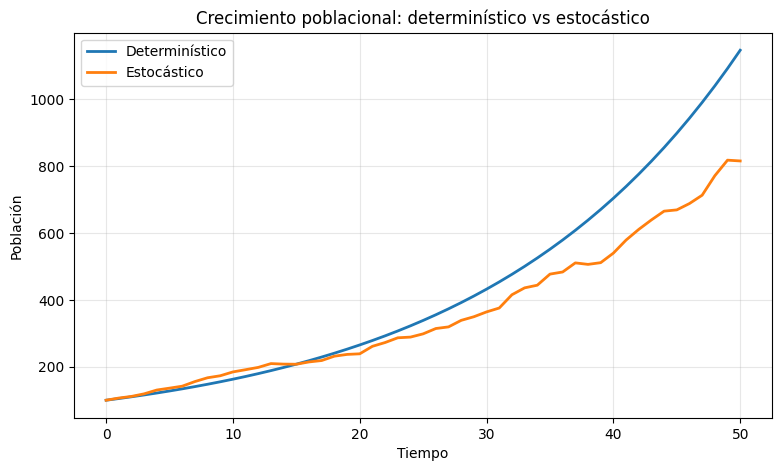

In [20]:
np.random.seed(SEED)

P0 = 100      # población inicial
r = 0.05      # tasa de crecimiento
sigma = 0.03  # desviación del ruido (solo para el estocástico)
T = 50        # periodos

# Modelo determinístico
det = [P0]
for t in range(T):
    det.append(det[-1] * (1 + r))

# Modelo estocástico (mismos parámetros + ruido)
est = [P0]
for t in range(T):
    ruido = np.random.normal(0, sigma)
    est.append(est[-1] * (1 + r + ruido))

plt.figure(figsize=(9, 5))
plt.plot(det, label="Determinístico", linewidth=2)
plt.plot(est, label="Estocástico", linewidth=2)
plt.xlabel("Tiempo")
plt.ylabel("Población")
plt.title("Crecimiento poblacional: determinístico vs estocástico")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El modelo determinístico produce una trayectoria suave y siempre idéntica,
porque utiliza parámetros fijos y no contiene ningún componente aleatorio: con
los mismos valores iniciales, el resultado se repite en cada ejecución. En
cambio, el modelo estocástico añade un ruido aleatorio a la tasa de
crecimiento, por lo que su trayectoria se desvía de la curva determinística;
en esta simulación, con semilla 42, termina por debajo de ella, y el resultado
cambiaría con otra semilla. Aunque ambos modelos parten de los mismos
parámetros, el estocástico refleja mejor la variabilidad de los fenómenos
reales. Incorporar incertidumbre es importante porque permite evaluar riesgos,
estimar rangos de resultados posibles y tomar decisiones más realistas, en
lugar de depender de una única predicción que rara vez coincide con lo
observado.

## Actividad 2. Generación de números y variables aleatorias

Se generan 1,000 números pseudoaleatorios con distribución uniforme U(0,1) y
1,000 observaciones de cada una de las siguientes distribuciones: Normal N(0,1),
Exponencial (λ = 1) y Poisson (λ = 5). Se fija la semilla en 42 para garantizar
la reproducibilidad. Se presentan histogramas (o gráficos de frecuencias para
la Poisson, que es discreta), estadísticos descriptivos y una comparación con
los valores teóricos de la media y la varianza.

In [21]:
rng = np.random.default_rng(42)
n = 1000

datos = {
    "Uniforme U(0,1)": rng.uniform(0, 1, n),
    "Normal N(0,1)": rng.normal(0, 1, n),
    "Exponencial λ=1": rng.exponential(scale=1, size=n),
    "Poisson λ=5": rng.poisson(lam=5, size=n),
}

# Valores teóricos (media, varianza)
teoricos = {
    "Uniforme U(0,1)": (0.5, 1/12),
    "Normal N(0,1)": (0, 1),
    "Exponencial λ=1": (1, 1),
    "Poisson λ=5": (5, 5),
}

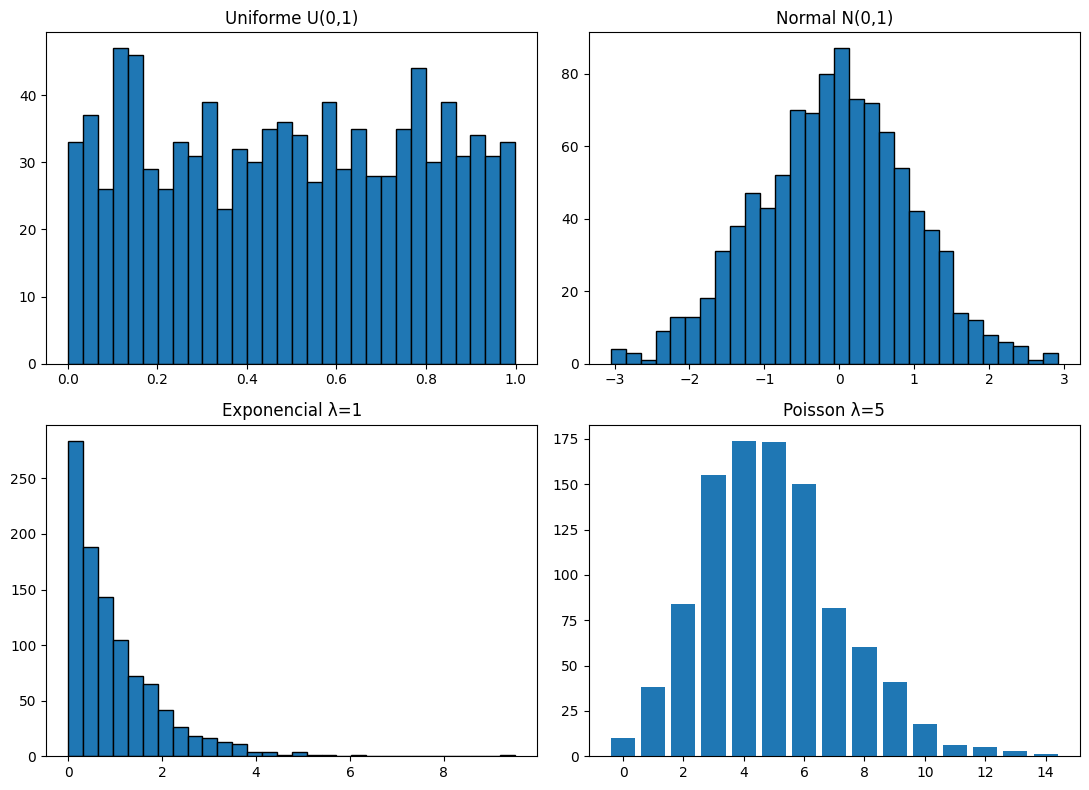

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, (nombre, x) in zip(axs.flat, datos.items()):
    if "Poisson" in nombre:
        valores, cuentas = np.unique(x, return_counts=True)
        ax.bar(valores, cuentas)
    else:
        ax.hist(x, bins=30, edgecolor="black")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [23]:
filas = []
for nombre, x in datos.items():
    mt, vt = teoricos[nombre]
    filas.append({
        "Distribución": nombre,
        "Media": x.mean(),
        "Varianza": x.var(ddof=1),
        "Desv. estándar": x.std(ddof=1),
        "Mínimo": x.min(),
        "Máximo": x.max(),
        "Media teórica": mt,
        "Varianza teórica": vt,
    })

tabla = pd.DataFrame(filas).round(4)

# Diferencias entre lo simulado y lo teórico
tabla["Dif. media"] = (tabla["Media"] - tabla["Media teórica"]).round(4)
tabla["Dif. varianza"] = (tabla["Varianza"] - tabla["Varianza teórica"]).round(4)

print("Estadísticos descriptivos")
display(tabla[["Distribución", "Media", "Varianza", "Desv. estándar", "Mínimo", "Máximo"]])

print("Comparación con los valores teóricos")
display(tabla[["Distribución", "Media", "Media teórica", "Dif. media",
               "Varianza", "Varianza teórica", "Dif. varianza"]])

Estadísticos descriptivos


,Distribución,Media,Varianza,Desv. estándar,Mínimo,Máximo
0,"Uniforme U(0,1)",0.4972,0.0850,0.2916,0.0012,0.9991
1,"Normal N(0,1)",-0.0779,1.0292,1.0145,-3.0476,2.9142
2,Exponencial λ=1,0.9862,0.9659,0.9828,0.0002,9.5181
3,Poisson λ=5,4.9140,5.2639,2.2943,0.0000,14.0000


Comparación con los valores teóricos


,Distribución,Media,Media teórica,Dif. media,Varianza,Varianza teórica,Dif. varianza
0,"Uniforme U(0,1)",0.4972,0.5,-0.0028,0.0850,0.0833,0.0017
1,"Normal N(0,1)",-0.0779,0.0,-0.0779,1.0292,1.0000,0.0292
2,Exponencial λ=1,0.9862,1.0,-0.0138,0.9659,1.0000,-0.0341
3,Poisson λ=5,4.9140,5.0,-0.0860,5.2639,5.0000,0.2639


Los datos simulados reproducen las características esperadas de cada
distribución. La uniforme U(0,1) tiene un histograma aproximadamente plano, con
media 0.497 (teórica 0.5) y varianza 0.085 (teórica 0.083). La normal estándar
forma una campana simétrica centrada cerca de 0, con media de −0.078 y varianza
de 1.029. La exponencial (λ = 1) es asimétrica a la derecha: abundan los
valores pequeños y hay pocos muy grandes, con máximo de 9.52; su media (0.986)
y varianza (0.966) quedan cerca de 1. La Poisson (λ = 5) es discreta, con media
4.914 y varianza 5.264, ambas cercanas a 5. La mayor diferencia absoluta se
observa en la varianza de la Poisson (+0.264), atribuible a la variabilidad
muestral, y se reduciría con más observaciones, conforme a la ley de los
grandes números.

## Conclusión

La comparación mostró que el modelo determinístico es reproducible pero no
captura la variabilidad, mientras que el estocástico incorpora la incertidumbre
mediante un componente aleatorio. Además, la generación de variables aleatorias
con semilla fija permitió obtener muestras reproducibles cuyas medias y
varianzas se aproximan a los valores teóricos, lo que confirma que la
simulación es una herramienta útil para estudiar fenómenos con incertidumbre.